# 02 — Exploratory Data Analysis

**Goal:** Find what drives customer churn and quantify it.

**Hypotheses to test:**
1. Short-tenure customers churn more
2. Month-to-month contract customers churn more
3. Fiber optic customers may behave differently (to be checked, not assumed)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

df = pd.read_csv("../data/processed/telco_clean.csv")
print("Loaded:", df.shape)

Loaded: (7043, 21)


## 1. Overall churn rate

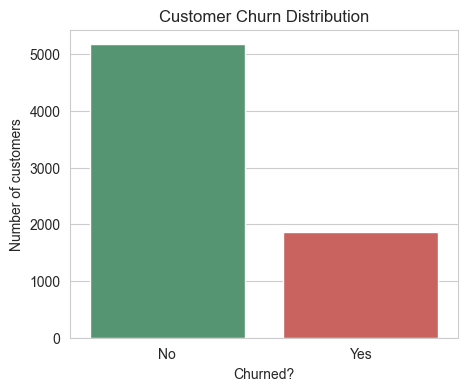

Churn rate: 26.5%


In [2]:
churn_counts = df["Churn"].value_counts()

plt.figure(figsize=(5, 4))
sns.countplot(data=df, x="Churn", palette=["#4C9F70", "#D9534F"])
plt.title("Customer Churn Distribution")
plt.xlabel("Churned?")
plt.ylabel("Number of customers")
plt.show()

print(f"Churn rate: {(df['Churn'] == 'Yes').mean():.1%}")

## 2. Does tenure affect churn?

Hypothesis: short-tenure customers churn more.
Approach: (a) compare the tenure distribution of churners vs stayers,
(b) group tenure into buckets and compare churn *rates*.

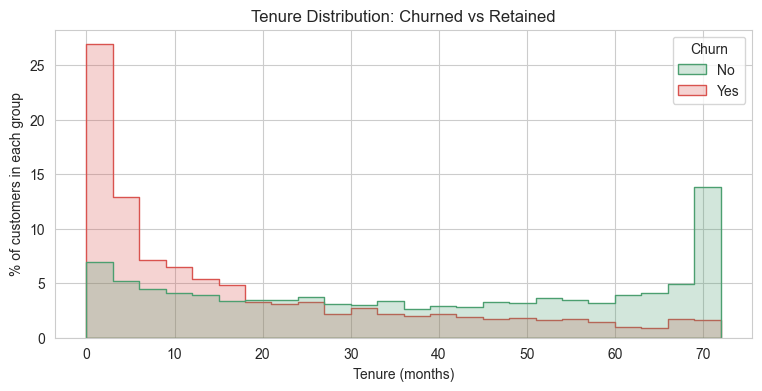

In [3]:
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)

plt.figure(figsize=(9, 4))
sns.histplot(data=df, x="tenure", hue="Churn", bins=24,
             stat="percent", common_norm=False, element="step",
             palette={"No": "#4C9F70", "Yes": "#D9534F"})
plt.title("Tenure Distribution: Churned vs Retained")
plt.xlabel("Tenure (months)")
plt.ylabel("% of customers in each group")
plt.show()

### Churn rate by tenure bucket

Grouping tenure into meaningful lifecycle stages for a clearer business view.

              Customers  ChurnRate
TenureGroup                       
0-12 months        2186       47.4
13-24 months       1024       28.7
25-48 months       1594       20.4
49-72 months       2239        9.5


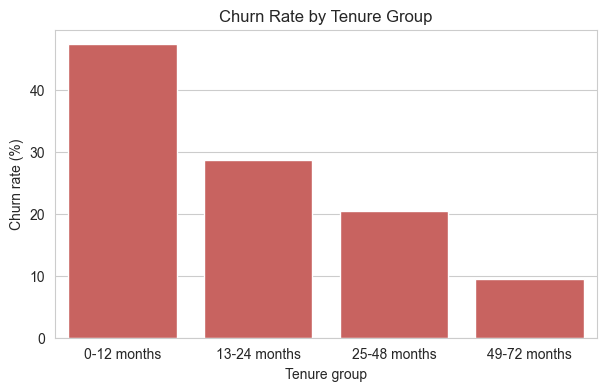

In [4]:
bins = [-1, 12, 24, 48, 72]
labels = ["0-12 months", "13-24 months", "25-48 months", "49-72 months"]
df["TenureGroup"] = pd.cut(df["tenure"], bins=bins, labels=labels)

tenure_churn = df.groupby("TenureGroup")["ChurnFlag"].agg(["count", "mean"])
tenure_churn.columns = ["Customers", "ChurnRate"]
tenure_churn["ChurnRate"] = (tenure_churn["ChurnRate"] * 100).round(1)
print(tenure_churn)

plt.figure(figsize=(7, 4))
sns.barplot(x=tenure_churn.index, y=tenure_churn["ChurnRate"], color="#D9534F")
plt.title("Churn Rate by Tenure Group")
plt.xlabel("Tenure group")
plt.ylabel("Churn rate (%)")
plt.show()

## 3. Does contract type affect churn?

Hypothesis: month-to-month customers churn more because they face no exit barrier.
Also checking how contract type overlaps with tenure.

                Customers  ChurnRate
Contract                            
Month-to-month       3875       42.7
One year             1473       11.3
Two year             1695        2.8


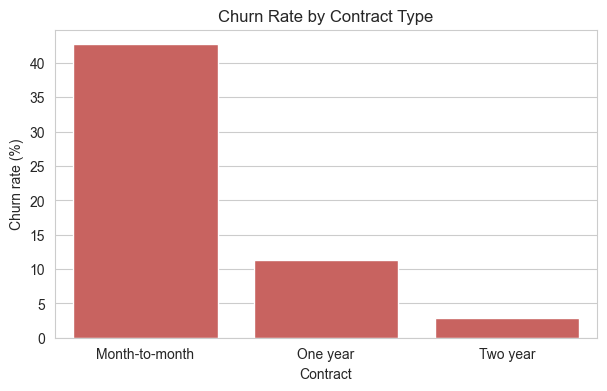

In [5]:
contract_churn = df.groupby("Contract")["ChurnFlag"].agg(["count", "mean"])
contract_churn.columns = ["Customers", "ChurnRate"]
contract_churn["ChurnRate"] = (contract_churn["ChurnRate"] * 100).round(1)
print(contract_churn)

plt.figure(figsize=(7, 4))
sns.barplot(x=contract_churn.index, y=contract_churn["ChurnRate"], color="#D9534F")
plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract")
plt.ylabel("Churn rate (%)")
plt.show()

### Are contract and tenure the same story?

Checking whether month-to-month customers are simply the newer customers.

In [6]:
overlap = pd.crosstab(df["TenureGroup"], df["Contract"], normalize="index") * 100
print(overlap.round(1))

pivot = df.pivot_table(index="TenureGroup", columns="Contract",
                       values="ChurnFlag", aggfunc="mean") * 100
print()
print(pivot.round(1))

Contract      Month-to-month  One year  Two year
TenureGroup                                     
0-12 months             91.2       5.7       3.1
13-24 months            72.0      19.2       8.8
25-48 months            50.3      32.5      17.2
49-72 months            15.3      28.3      56.4

Contract      Month-to-month  One year  Two year
TenureGroup                                     
0-12 months             51.4      10.5       0.0
13-24 months            37.7       8.1       0.0
25-48 months            32.9      10.6       2.2
49-72 months            26.0      12.9       3.3


## 4. Does internet service type affect churn?

Earlier hunch: fiber optic customers might not matter. Testing it with data.
Checking churn rate by service type, then whether price or contract explains it.

                 Customers  ChurnRate  AvgMonthlyCharge
InternetService                                        
DSL                   2421       19.0             58.10
Fiber optic           3096       41.9             91.50
No                    1526        7.4             21.08


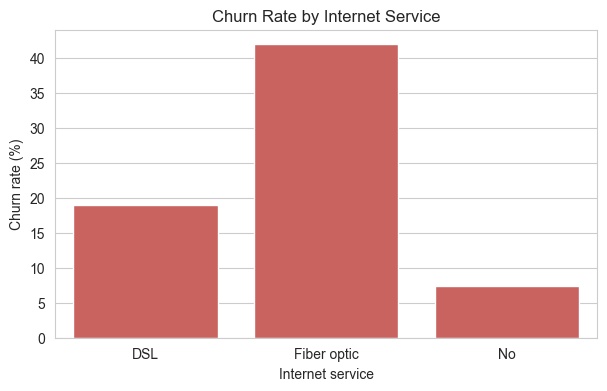

In [7]:
internet_churn = df.groupby("InternetService").agg(
    Customers=("ChurnFlag", "count"),
    ChurnRate=("ChurnFlag", "mean"),
    AvgMonthlyCharge=("MonthlyCharges", "mean")
)
internet_churn["ChurnRate"] = (internet_churn["ChurnRate"] * 100).round(1)
internet_churn["AvgMonthlyCharge"] = internet_churn["AvgMonthlyCharge"].round(2)
print(internet_churn)

plt.figure(figsize=(7, 4))
sns.barplot(x=internet_churn.index, y=internet_churn["ChurnRate"], color="#D9534F")
plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet service")
plt.ylabel("Churn rate (%)")
plt.show()

### Is fiber churn explained by contract type?

Checking whether fiber customers churn more even within the same contract type.

In [8]:
fiber_pivot = df.pivot_table(index="InternetService", columns="Contract",
                             values="ChurnFlag", aggfunc="mean") * 100
print(fiber_pivot.round(1))

print()
print(pd.crosstab(df["InternetService"], df["Contract"], normalize="index").round(3) * 100)

Contract         Month-to-month  One year  Two year
InternetService                                    
DSL                        32.2       9.3       1.9
Fiber optic                54.6      19.3       7.2
No                         18.9       2.5       0.8

Contract         Month-to-month  One year  Two year
InternetService                                    
DSL                        50.5      23.5      25.9
Fiber optic                68.7      17.4      13.9
No                         34.3      23.9      41.8


## 5. Why does fiber churn more? Testing two ideas

Idea 1: fiber customers without support/protection add-ons churn more.
Idea 2: price pressure — churners pay more per month.
Restricting to fiber customers only, so we compare like with like.

In [9]:
fiber = df[df["InternetService"] == "Fiber optic"]

addon_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
              "TechSupport", "StreamingTV", "StreamingMovies"]

rows = []
for col in addon_cols:
    rates = fiber.groupby(col)["ChurnFlag"].mean() * 100
    rows.append({"Add-on": col,
                 "Churn % with add-on": rates["Yes"],
                 "Churn % without": rates["No"]})

addon_table = pd.DataFrame(rows).round(1)
addon_table["Gap (pts)"] = (addon_table["Churn % without"]
                            - addon_table["Churn % with add-on"]).round(1)
print(addon_table)

             Add-on  Churn % with add-on  Churn % without  Gap (pts)
0    OnlineSecurity                 21.8             49.4       27.6
1      OnlineBackup                 30.3             50.8       20.5
2  DeviceProtection                 31.5             50.0       18.5
3       TechSupport                 22.6             49.4       26.8
4       StreamingTV                 39.3             45.3        6.0
5   StreamingMovies                 38.9             45.8        6.9


       count   mean  median
Churn                      
No      1799  93.93   94.80
Yes     1297  88.13   87.55


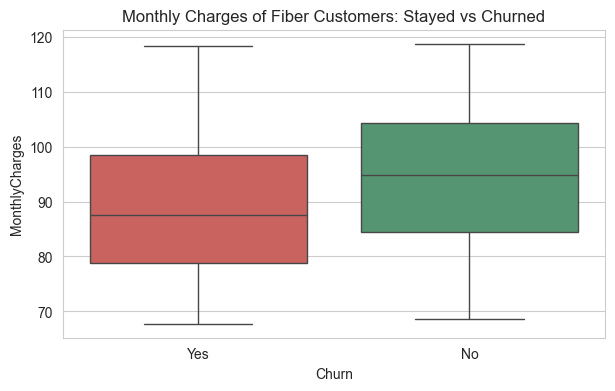

In [10]:
price_by_churn = fiber.groupby("Churn")["MonthlyCharges"].agg(["count", "mean", "median"]).round(2)
print(price_by_churn)

plt.figure(figsize=(7, 4))
sns.boxplot(data=fiber, x="Churn", y="MonthlyCharges",
            palette={"No": "#4C9F70", "Yes": "#D9534F"})
plt.title("Monthly Charges of Fiber Customers: Stayed vs Churned")
plt.show()

## 6. High-risk segment

Combining the four signals found so far: month-to-month contract, fiber optic,
tenure 0-12 months, and no tech support. How concentrated is churn in this segment?

In [11]:
risk_seg = df[
    (df["Contract"] == "Month-to-month")
    & (df["InternetService"] == "Fiber optic")
    & (df["TenureGroup"] == "0-12 months")
    & (df["TechSupport"] == "No")
]

seg_customers = len(risk_seg)
seg_churn_rate = risk_seg["ChurnFlag"].mean() * 100
share_of_customers = seg_customers / len(df) * 100
share_of_churners = risk_seg["ChurnFlag"].sum() / df["ChurnFlag"].sum() * 100

print(f"Segment size: {seg_customers} customers ({share_of_customers:.1f}% of base)")
print(f"Segment churn rate: {seg_churn_rate:.1f}%")
print(f"Share of ALL churners in this segment: {share_of_churners:.1f}%")

Segment size: 833 customers (11.8% of base)
Segment churn rate: 71.1%
Share of ALL churners in this segment: 31.7%


## EDA summary

1. Overall churn rate is about 26.5%; roughly 1 in 4 customers leaves.
2. **Tenure:** churn falls steadily from 47.4% (0-12 months) to 9.5% (49-72 months).
3. **Contract:** month-to-month 42.7% vs two-year 2.8%; the effect persists within tenure groups.
4. **Internet service:** fiber churns at 41.9% vs DSL 19.0%, across all contract types.
5. **Price is not the driver:** among fiber customers, churners pay less than stayers.
6. **Protective add-ons** (online security, tech support) are associated with ~27 points lower churn among fiber customers. Association, not proven causation.
7. A small high-risk segment (month-to-month, fiber, new, no support) holds a disproportionate share of churn.